# 03 — Inference & Fleet Curtailment Quantification Demo

Interactive demonstration of `MicrogridForecaster` on anonymized synthetic microgrids (`MG-SITE-*`):
1. Inspect the available site catalog.
2. Execute simultaneous 15-minute solar, load, and counterfactual curtailment forecasting for `MG-SITE-001`.
3. Render the 4-panel executive forecast dashboard and fleet curtailment ranking.

In [1]:
from pathlib import Path
import sys
from IPython.display import Image, display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from microgrid_ml.config import load_config
from microgrid_ml.inference.predictor import MicrogridForecaster, load_features_parquet
from microgrid_ml.visualization.plots import (
    plot_fleet_curtailment_ranking,
    plot_site_forecast_dashboard,
)

cfg = load_config(repo_root=REPO_ROOT)
df_features = load_features_parquet(cfg)
forecaster = MicrogridForecaster(cfg)

forecaster.list_sites(df_features, top_n=10)

site_id,region_zone,topology,solar_capacity_kwp,latitude,longitude,daytime_intervals
cat,cat,cat,f32,f32,f32,u32
"""MG-SITE-001""","""Zone-Equatorial-Grid""","""Hybrid-Solar-Battery-Genset""",18.0,7.322,-45.243999,10882
"""MG-SITE-002""","""Zone-Tropical-Grid""","""Hybrid-Solar-Battery-Genset""",30.0,14.264,-45.639,10998
"""MG-SITE-003""","""Zone-Subtropical-Grid""","""OffGrid-Solar-Battery""",30.0,-16.996,-133.014008,10575
"""MG-SITE-004""","""Zone-Equatorial-Grid""","""Hybrid-Solar-Battery-Genset""",15.2,6.266,-44.639,10901
"""MG-SITE-005""","""Zone-Tropical-Grid""","""Hybrid-Solar-Battery-Genset""",12.6,14.627,-46.168999,11011
"""MG-SITE-006""","""Zone-Subtropical-Grid""","""OffGrid-Solar-Battery""",24.0,-17.478001,-134.873001,10596
"""MG-SITE-007""","""Zone-Equatorial-Grid""","""Hybrid-Solar-Battery-Genset""",24.0,6.07,-45.855999,10925
"""MG-SITE-008""","""Zone-Tropical-Grid""","""Hybrid-Solar-Battery-Genset""",18.0,14.915,-44.935001,11013
"""MG-SITE-009""","""Zone-Subtropical-Grid""","""OffGrid-Solar-Battery""",15.2,-16.072001,-134.621994,10634


Site: MG-SITE-001 (Hybrid-Solar-Battery-Genset, 18.00 kWp)
Forecast Solar:   267.7 kWh | Actual: 288.9 kWh
Curtailed Energy: 148.9 kWh (34.0% of potential)
Avoidable Diesel: 44.7 L (~$49.13 USD)


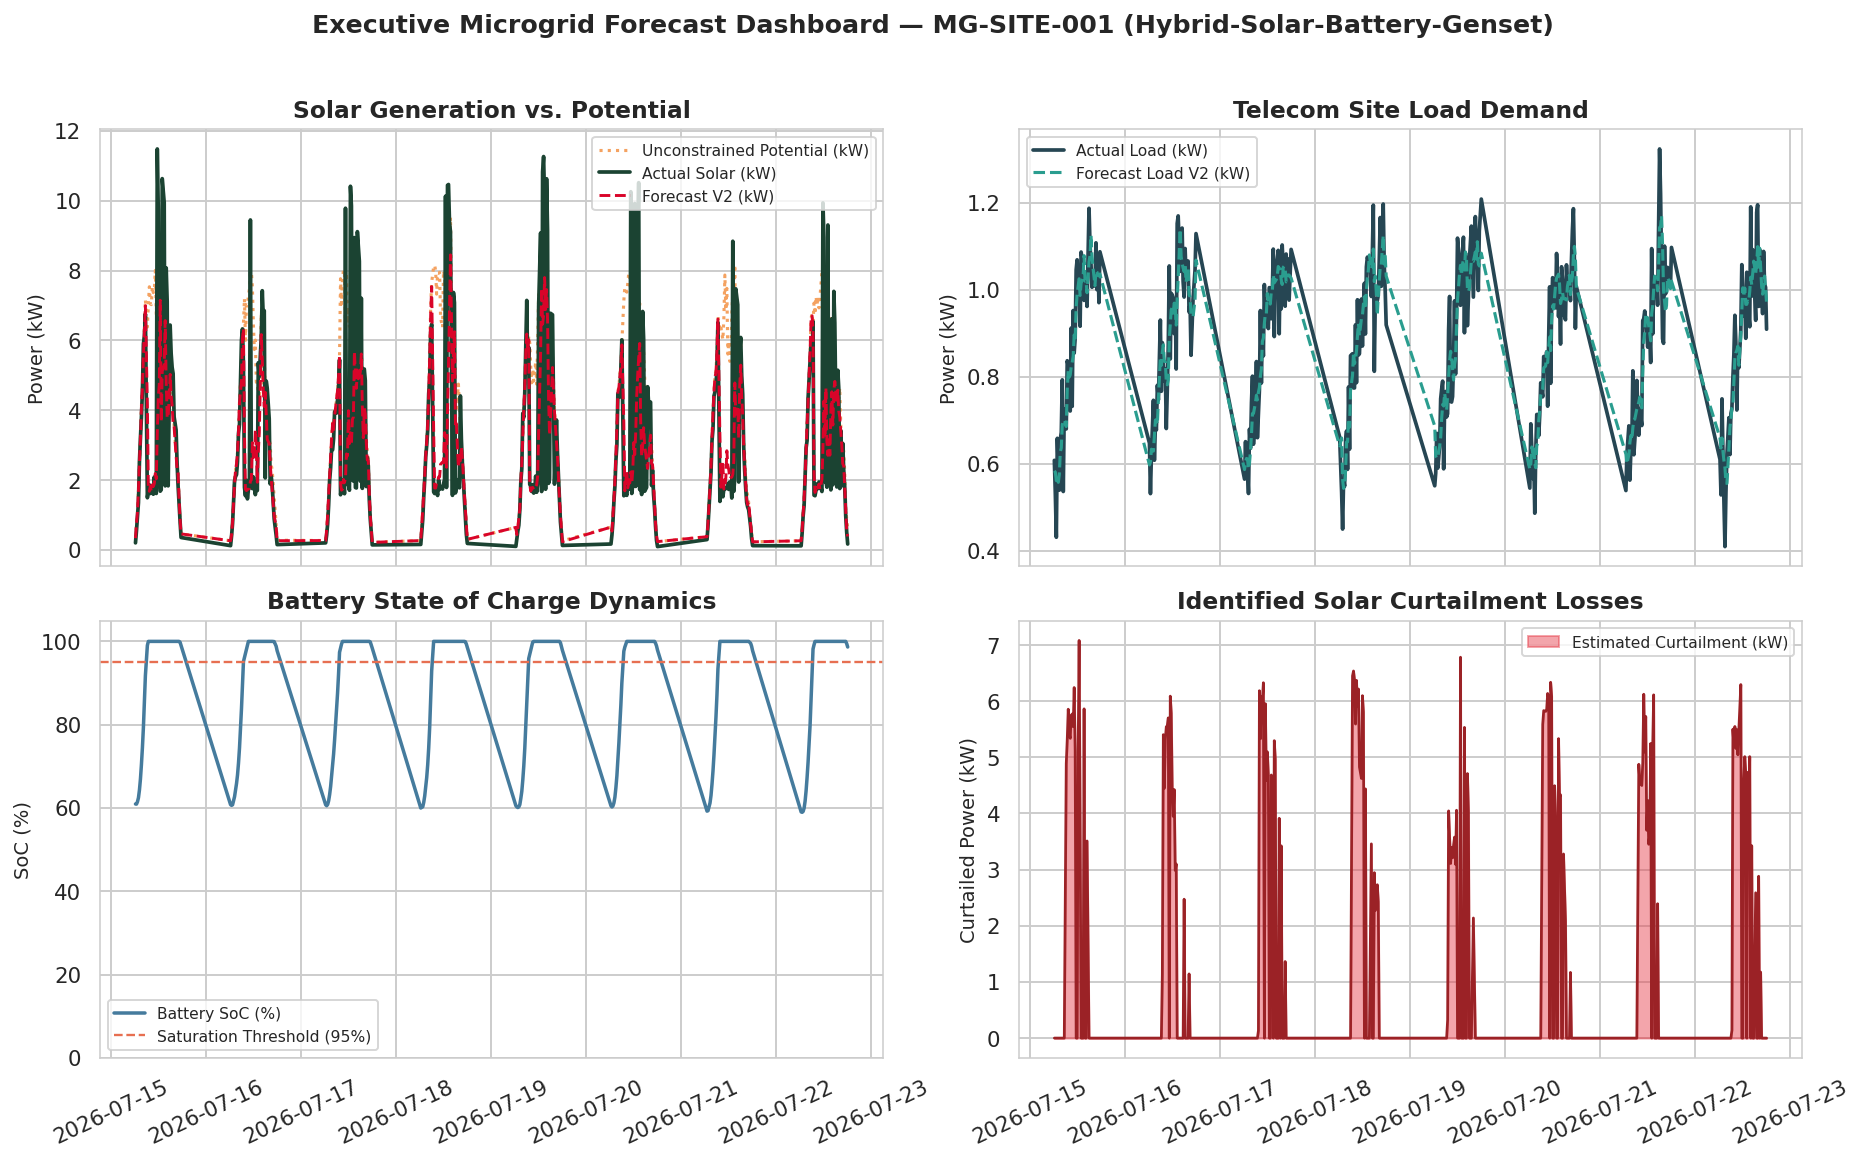

In [2]:
df_fc = forecaster.forecast_site(
    df_features,
    site_id="MG-SITE-001",
    start_date="2026-07-15",
    end_date="2026-07-23",
    max_rows=672,
)
summary = forecaster.summarize_forecast(df_fc)

print(f"Site: {summary.site_id} ({summary.topology}, {summary.solar_capacity_kwp:.2f} kWp)")
print(f"Forecast Solar:   {summary.forecast_solar_kwh:.1f} kWh | Actual: {summary.actual_solar_kwh:.1f} kWh")
print(f"Curtailed Energy: {summary.curtailed_kwh:.1f} kWh ({summary.curtailment_pct_of_potential:.1f}% of potential)")
print(f"Avoidable Diesel: {summary.avoidable_diesel_liters:.1f} L (~${summary.avoidable_diesel_usd:.2f} USD)")

dash_fig = plot_site_forecast_dashboard(df_fc, cfg.figures_dir / "site_forecast_dashboard.png")
display(Image(filename=str(dash_fig)))

site_id,region_zone,topology,solar_capacity_kwp,curtailed_kwh,actual_solar_kwh,curtailment_intervals,avoidable_diesel_liters,avoidable_diesel_usd
cat,cat,cat,f32,f32,f32,i64,f32,f32
"""MG-SITE-009""","""Zone-Subtropical-Grid""","""OffGrid-Solar-Battery""",15.2,8941.556641,4426.419922,7599,2682.467041,2950.713867
"""MG-SITE-003""","""Zone-Subtropical-Grid""","""OffGrid-Solar-Battery""",30.0,7669.970703,18506.484375,3586,2300.991211,2531.090332
"""MG-SITE-007""","""Zone-Equatorial-Grid""","""Hybrid-Solar-Battery-Genset""",24.0,6646.958984,15858.487305,3748,1994.087769,2193.496582
"""MG-SITE-001""","""Zone-Equatorial-Grid""","""Hybrid-Solar-Battery-Genset""",18.0,5066.582031,9710.6875,4326,1519.974609,1671.972046
"""MG-SITE-005""","""Zone-Tropical-Grid""","""Hybrid-Solar-Battery-Genset""",12.6,4286.134277,6404.474121,5403,1285.840332,1414.424438
"""MG-SITE-002""","""Zone-Tropical-Grid""","""Hybrid-Solar-Battery-Genset""",30.0,0.0,28611.613281,0,0.0,0.0
"""MG-SITE-008""","""Zone-Tropical-Grid""","""Hybrid-Solar-Battery-Genset""",18.0,0.0,19913.533203,0,0.0,0.0
"""MG-SITE-006""","""Zone-Subtropical-Grid""","""OffGrid-Solar-Battery""",24.0,0.0,23018.458984,0,0.0,0.0
"""MG-SITE-004""","""Zone-Equatorial-Grid""","""Hybrid-Solar-Battery-Genset""",15.2,0.0,16310.105469,0,0.0,0.0


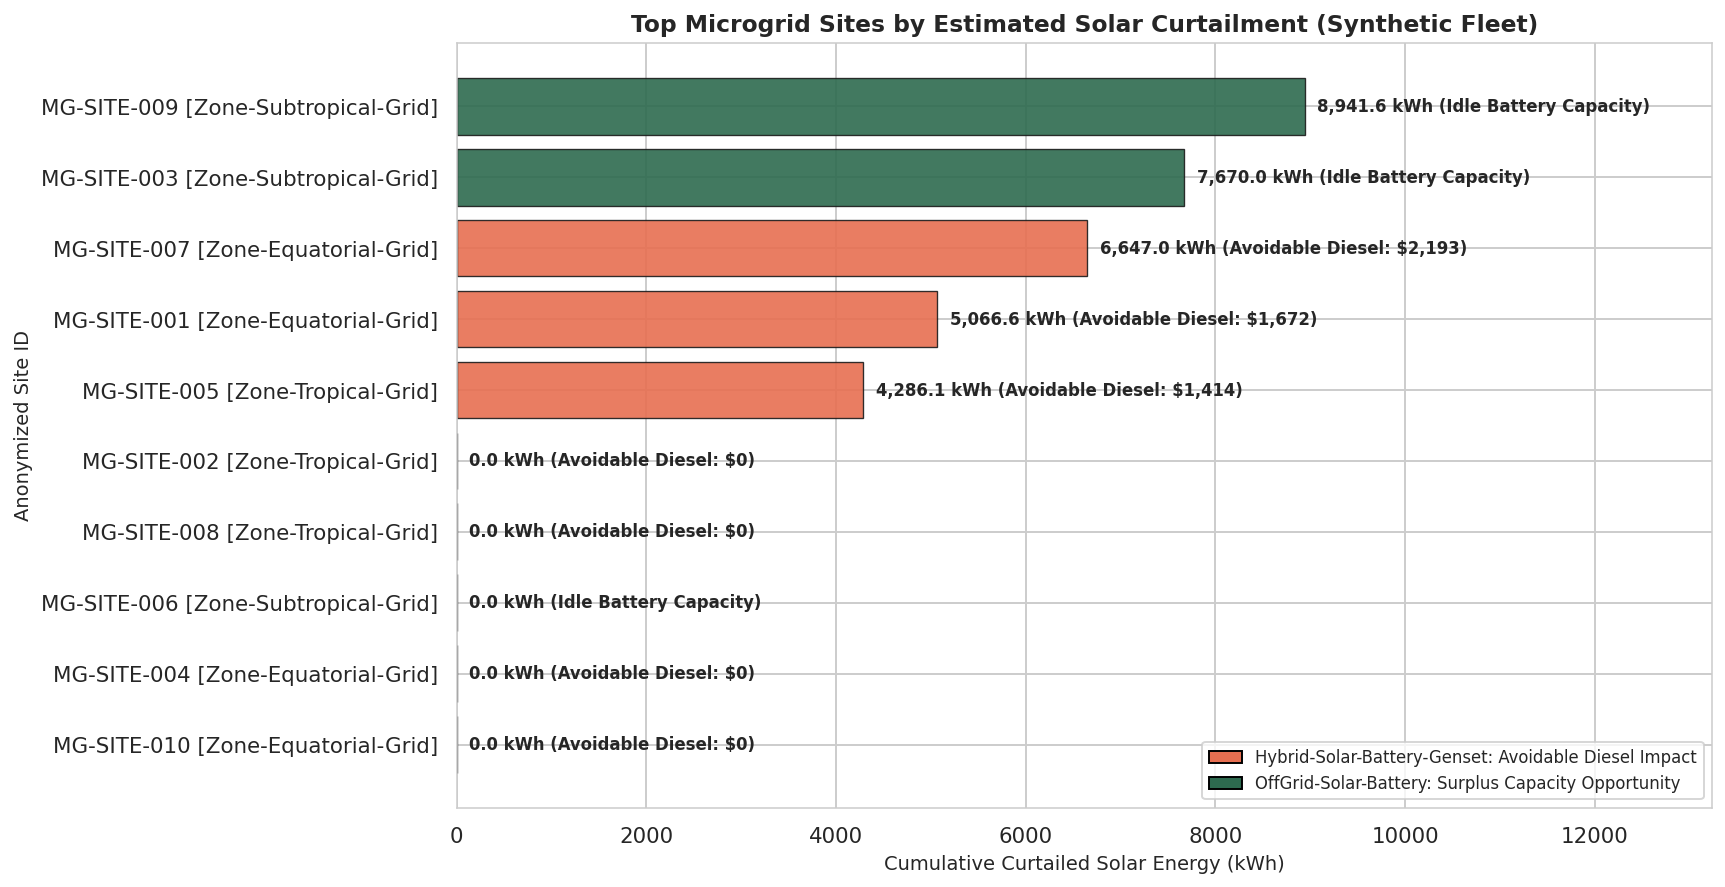

In [3]:
ranking = forecaster.rank_fleet_curtailment(df_features, top_n=15)
display(ranking)

rank_fig = plot_fleet_curtailment_ranking(ranking, cfg.figures_dir / "fleet_curtailment_ranking.png")
display(Image(filename=str(rank_fig)))